# Etapa 1 — primeira simulação real com o RuFaS

Este notebook configura um cenário animal, envia a solicitação ao worker por um volume compartilhado, aguarda o RuFaS e apresenta resultados reais. A otimização externa e a análise de sensibilidade ainda não são executadas.

## 1. Introdução e preparação

In [24]:
import copy
import os
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from rufas_project import (
    DietConfig, DietIngredient, EconomicConfig, HerdConfig, MilkConfig,
    ParityFractions, SimulationConfig, calculate_economics, compare_scenarios,
    load_result, submit_simulation, validate_simulation_config, wait_for_simulation,
)

SHARED_ROOT = Path(os.getenv('SHARED_ROOT', '/workspace/shared'))

TABLE_STYLES = [
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 0')]},
    {'selector': 'th', 'props': [('background-color', '#256a4b'), ('color', 'white'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '7px 12px'), ('border-bottom', '1px solid #e5e7eb')]},
]

def show_table(frame, caption, hide_index=True):
    styled = frame.style.set_caption(caption).set_table_styles(TABLE_STYLES)
    if hide_index:
        styled = styled.hide(axis='index')
    display(styled)

environment_summary = pd.DataFrame([
    ('Ambiente de execução', 'Jupyter + worker RuFaS'),
    ('Diretório compartilhado', str(SHARED_ROOT)),
    ('Comunicação', 'Fila de arquivos gerada automaticamente'),
], columns=['Item', 'Descrição'])
show_table(environment_summary, 'Ambiente preparado')

Item,Descrição
Ambiente de execução,Jupyter + worker RuFaS
Diretório compartilhado,/workspace/shared
Comunicação,Fila de arquivos gerada automaticamente


## 2. Configuração da fazenda

Todos os valores do experimento são definidos nas células deste notebook. Na execução, o módulo Python combina esses valores com o cenário oficial `animals_only`, NASEM e os demais arquivos oficiais do RuFaS, criando cópias isoladas sem alterar os exemplos originais.

In [25]:
reference = SimulationConfig(
    name='dieta_referencia',
    simulation_days=30,
    random_seed=42,
)
farm_summary = pd.DataFrame([
    ('Nome do cenário', reference.name),
    ('Duração da simulação', f'{reference.simulation_days} dias'),
    ('Semente aleatória', reference.random_seed),
    ('Padrão nutricional', 'NASEM'),
    ('Escopo da simulação', 'Somente animais (animals_only)'),
], columns=['Parâmetro', 'Valor'])
show_table(farm_summary, 'Configuração geral da fazenda')

Parâmetro,Valor
Nome do cenário,dieta_referencia
Duração da simulação,30 dias
Semente aleatória,42
Padrão nutricional,NASEM
Escopo da simulação,Somente animais (animals_only)


## 3. Configuração do rebanho e da lactação

In [15]:
reference.herd = HerdConfig(
    cow_num=20,
    milking_cow_fraction=0.80,
    breed='HO',  # HO = Holandesa; JE = Jersey
    parity_fractions=ParityFractions(
        parity_1=0.40,
        parity_2=0.25,
        parity_3=0.20,
        parity_4=0.10,
        parity_5=0.05,
    ),
)
reference.milk = MilkConfig(
    fat_percent=4.0,
    protein_percent=3.2,
    mature_body_weight_kg=740.1,
)
herd_and_milk_summary = pd.DataFrame([
    ('Rebanho', 'Total de vacas', f'{reference.herd.cow_num} animais'),
    ('Rebanho', 'Vacas em lactação (estimativa)', f'{reference.herd.cow_num * reference.herd.milking_cow_fraction:.0f} animais'),
    ('Rebanho', 'Fração em lactação', f'{reference.herd.milking_cow_fraction:.0%}'),
    ('Rebanho', 'Raça', {'HO': 'Holandesa', 'JE': 'Jersey'}[reference.herd.breed]),
    ('Paridade', '1ª lactação', f'{reference.herd.parity_fractions.parity_1:.0%}'),
    ('Paridade', '2ª lactação', f'{reference.herd.parity_fractions.parity_2:.0%}'),
    ('Paridade', '3ª lactação', f'{reference.herd.parity_fractions.parity_3:.0%}'),
    ('Paridade', '4ª lactação', f'{reference.herd.parity_fractions.parity_4:.0%}'),
    ('Paridade', '5ª lactação ou mais', f'{reference.herd.parity_fractions.parity_5:.0%}'),
    ('Leite', 'Gordura', f'{reference.milk.fat_percent:.1f}%'),
    ('Leite', 'Proteína', f'{reference.milk.protein_percent:.1f}%'),
    ('Animal', 'Peso corporal adulto', f'{reference.milk.mature_body_weight_kg:.1f} kg'),
], columns=['Grupo', 'Parâmetro', 'Valor'])

herd_style = (
    herd_and_milk_summary.style
    .hide(axis='index')
    .set_caption('Resumo do rebanho e dos parâmetros de lactação')
    .set_table_styles(TABLE_STYLES)
    .set_properties(subset=['Grupo'], **{'font-weight': 'bold', 'color': '#256a4b'})
)
display(herd_style)

Grupo,Parâmetro,Valor
Rebanho,Total de vacas,20 animais
Rebanho,Vacas em lactação (estimativa),16 animais
Rebanho,Fração em lactação,80%
Rebanho,Raça,Holandesa
Paridade,1ª lactação,40%
Paridade,2ª lactação,25%
Paridade,3ª lactação,20%
Paridade,4ª lactação,10%
Paridade,5ª lactação ou mais,5%
Leite,Gordura,4.0%


## 4. Configuração da dieta

Os ingredientes abaixo são definidos diretamente no notebook. Seus IDs e valores iniciais foram copiados de `example_Midwest_feed.json`. Os percentuais estão em matéria seca e devem somar 100% no modo de receita fixa.

In [16]:
reference.diet = DietConfig(
    mode='fixed',  # use 'rufas_min_cost' para o otimizador interno SLSQP
    formulation_interval_days=30,
    ingredients=[
        DietIngredient(23, 0.74, 0.10, 'Blood meal, low dRUP'),
        DietIngredient(44, 15.31, 0.50, 'Corn grain dry, medium grind'),
        DietIngredient(50, 37.45, 0.01, 'Corn silage, immature'),
        DietIngredient(104, 0.37, 0.01, 'Grass/legume mix, legume silage'),
        DietIngredient(110, 17.65, 0.01, 'Legume silage, mid-maturity'),
        DietIngredient(301, 3.27, 1.00, 'Farm ES Mineral Mix'),
        DietIngredient(302, 25.21, 0.10, 'Farm ES Midwest BP Blend'),
    ],
)
ingredient_names_pt = {
    23: 'Farinha de sangue, baixo teor de proteína digestível não degradável no rúmen (dRUP)',
    44: 'Grão de milho seco, moagem média',
    50: 'Silagem de milho imatura',
    104: 'Mistura de gramínea e leguminosa ensilada',
    110: 'Silagem de leguminosa em maturação intermediária',
    301: 'Mistura mineral da fazenda (ES)',
    302: 'Mistura proteica de subprodutos do Meio-Oeste (BP)',
}

diet_table = pd.DataFrame([
    {
        'ID no RuFaS': item.feed_type,
        'Ingrediente em português': ingredient_names_pt[item.feed_type],
        'Nome original no RuFaS': item.name,
        'Participação na dieta': f'{item.ration_percentage:.2f}%',
        'Custo (USD/kg de MS)': f'{item.purchased_feed_cost_usd_per_kg_dm:.2f}',
    }
    for item in reference.diet.ingredients
])

show_table(diet_table, 'Ingredientes da dieta de referência')
diet_total = sum(item.ration_percentage for item in reference.diet.ingredients)
print(f'Soma da dieta: {diet_total:.2f}%')

ID no RuFaS,Ingrediente em português,Nome original no RuFaS,Participação na dieta,Custo (USD/kg de MS)
23,"Farinha de sangue, baixo teor de proteína digestível não degradável no rúmen (dRUP)","Blood meal, low dRUP",0.74%,0.10
44,"Grão de milho seco, moagem média","Corn grain dry, medium grind",15.31%,0.50
50,Silagem de milho imatura,"Corn silage, immature",37.45%,0.01
104,Mistura de gramínea e leguminosa ensilada,"Grass/legume mix, legume silage",0.37%,0.01
110,Silagem de leguminosa em maturação intermediária,"Legume silage, mid-maturity",17.65%,0.01
301,Mistura mineral da fazenda (ES),Farm ES Mineral Mix,3.27%,1.00
302,Mistura proteica de subprodutos do Meio-Oeste (BP),Farm ES Midwest BP Blend,25.21%,0.10


Soma da dieta: 100.00%


## 5. Parâmetros econômicos

O preço do leite não é uma saída do RuFaS nesta execução. Ele é uma hipótese externa, com unidade e origem registradas. Os custos dos alimentos são informados em USD/kg de matéria seca.

In [17]:
reference.economics = EconomicConfig(
    milk_price_usd_per_kg=0.45,
    milk_price_source=(
        'Hipótese didática; confirmar fonte, região e data antes da análise final'
    ),
    currency='USD',
)
economic_inputs = pd.DataFrame([
    ('Preço do leite', f'{reference.economics.milk_price_usd_per_kg:.2f} {reference.economics.currency}/kg'),
    ('Moeda', reference.economics.currency),
    ('Origem do preço', reference.economics.milk_price_source),
], columns=['Parâmetro econômico', 'Valor'])
show_table(economic_inputs, 'Premissas econômicas')

Parâmetro econômico,Valor
Preço do leite,0.45 USD/kg
Moeda,USD
Origem do preço,"Hipótese didática; confirmar fonte, região e data antes da análise final"


## 6. Validação das entradas

In [18]:
validate_simulation_config(reference)
validation_summary = pd.DataFrame([
    ('Configuração geral', 'Válida'),
    ('Soma da dieta', f'{diet_total:.2f}%'),
    ('Soma das paridades', '100%'),
    ('Pronto para simular', 'Sim'),
], columns=['Verificação', 'Resultado'])
show_table(validation_summary, 'Validação das entradas concluída')

Verificação,Resultado
Configuração geral,Válida
Soma da dieta,100.00%
Soma das paridades,100%
Pronto para simular,Sim


## 7. Execução da simulação

`submit_simulation` grava uma solicitação atômica no volume. O serviço `rufas-worker` detecta a fila, prepara os JSONs, executa `main.py` e registra logs e resultados no diretório do UUID.

In [19]:
reference_job = submit_simulation(reference, SHARED_ROOT)
reference_status = wait_for_simulation(reference_job, SHARED_ROOT, timeout_seconds=1800)
reference_result = load_result(reference_job, SHARED_ROOT)
execution_summary = pd.DataFrame([
    ('Identificador da execução', reference_job),
    ('Cenário', reference_status['scenario']),
    ('Situação final', 'Concluída com sucesso'),
    ('Mensagem', reference_status['message']),
], columns=['Item', 'Valor'])
show_table(execution_summary, 'Execução do RuFaS')

queued: Solicitação gravada; aguardando o worker do RuFaS
running: Executando o main.py do RuFaS
succeeded: Simulação concluída e resultados processados


Item,Valor
Identificador da execução,6973326f-d580-455d-8e73-436380484c89
Cenário,dieta_referencia
Situação final,Concluída com sucesso
Mensagem,Simulação concluída e resultados processados


## 8. Leitura dos resultados

In [20]:
reference_series = pd.DataFrame(reference_result['series'])
metrics = reference_result['metrics']
metrics_summary = pd.DataFrame([
    ('Vacas em lactação no início', f"{metrics['initial_lactating_cows']:.0f} animais"),
    ('Vacas em lactação ao final', f"{metrics['final_lactating_cows']:.0f} animais"),
    ('Vacas secas ao final', f"{metrics['final_dry_cows']:.0f} animais"),
    ('Total de vacas ao final', f"{metrics['final_total_cows']:.0f} animais"),
    ('Produção total de leite', f"{metrics['total_milk_kg']:,.2f} kg"),
    ('Produção média diária', f"{metrics['average_daily_milk_kg']:,.2f} kg/dia"),
    ('Pico de produção diária', f"{metrics['peak_daily_milk_kg']:,.2f} kg/dia"),
    ('Média de dias em lactação ao final', f"{metrics['final_avg_days_in_milk']:.1f} dias"),
], columns=['Indicador', 'Resultado'])
show_table(metrics_summary, 'Principais resultados produzidos pelo RuFaS')

daily_preview = reference_series.assign(
    total_feed_kg_dm=reference_series['lactating_feed_kg_dm'].map(
        lambda feeds: sum(feeds.values())
    )
)[[
    'day', 'lactating_cows', 'dry_cows', 'total_cows',
    'milk_kg', 'avg_days_in_milk', 'total_feed_kg_dm',
]].rename(columns={
    'day': 'Dia',
    'lactating_cows': 'Vacas em lactação',
    'dry_cows': 'Vacas secas',
    'total_cows': 'Total de vacas',
    'milk_kg': 'Leite (kg/dia)',
    'avg_days_in_milk': 'Dias em lactação (média)',
    'total_feed_kg_dm': 'Dieta ofertada (kg MS/dia)',
})
daily_style = (
    daily_preview.head().style
    .hide(axis='index')
    .set_caption('Primeiros cinco dias da simulação')
    .set_table_styles(TABLE_STYLES)
    .format({
        'Vacas em lactação': '{:.0f}', 'Vacas secas': '{:.0f}', 'Total de vacas': '{:.0f}',
        'Leite (kg/dia)': '{:,.2f}', 'Dias em lactação (média)': '{:.1f}',
        'Dieta ofertada (kg MS/dia)': '{:,.2f}',
    })
)
display(daily_style)

Indicador,Resultado
Vacas em lactação no início,15 animais
Vacas em lactação ao final,20 animais
Vacas secas ao final,4 animais
Total de vacas ao final,24 animais
Produção total de leite,"22,442.17 kg"
Produção média diária,748.07 kg/dia
Pico de produção diária,829.75 kg/dia
Média de dias em lactação ao final,85.0 dias


Dia,Vacas em lactação,Vacas secas,Total de vacas,Leite (kg/dia),Dias em lactação (média),Dieta ofertada (kg MS/dia)
1,15,4,19,624.90,121.3,415.13
2,16,4,20,643.38,114.7,442.80
3,16,4,20,651.71,115.7,442.80
4,17,4,21,669.89,109.9,470.48
5,17,4,21,675.21,110.9,470.48


## 9. Visualização

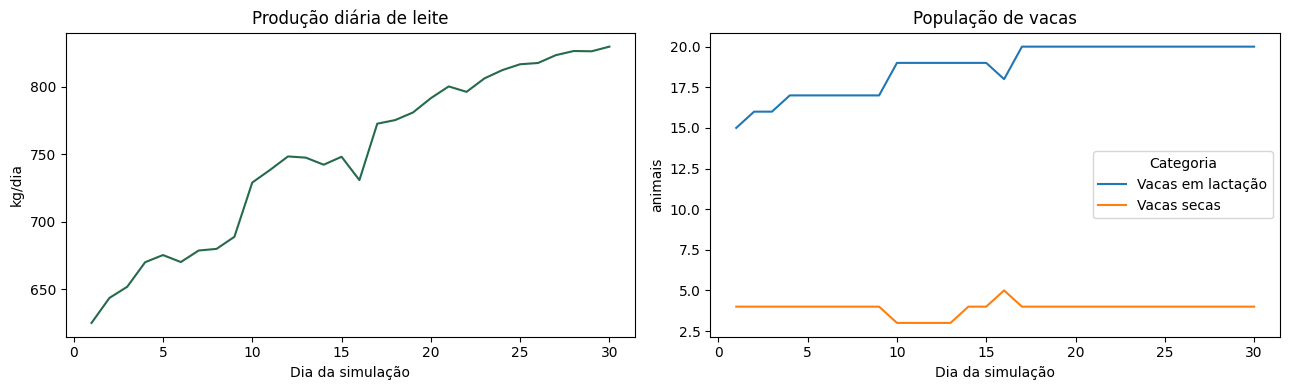

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
reference_series.plot(x='day', y='milk_kg', ax=axes[0], color='#256a4b', title='Produção diária de leite', legend=False)
reference_series.plot(x='day', y=['lactating_cows', 'dry_cows'], ax=axes[1], title='População de vacas')
axes[0].set_xlabel('Dia da simulação')
axes[0].set_ylabel('kg/dia')
axes[1].set_xlabel('Dia da simulação')
axes[1].set_ylabel('animais')
axes[1].legend(['Vacas em lactação', 'Vacas secas'], title='Categoria')
plt.tight_layout()

## 10. Avaliação econômica

A produção e o consumo vêm do RuFaS. Receita, custo e margem abaixo são calculados pelo projeto usando os preços informados. A margem considera apenas receita do leite menos alimentação das vacas em lactação.

In [22]:
reference_economics = calculate_economics(reference_result, reference)
economic_summary = pd.DataFrame([
    ('Origem dos cálculos', reference_economics['source']),
    ('Preço do leite', f"{reference_economics['milk_price_per_kg']:.2f} {reference_economics['currency']}/kg"),
    ('Receita total do leite', f"{reference_economics['total_milk_revenue']:,.2f} {reference_economics['currency']}"),
    ('Custo da alimentação das vacas em lactação', f"{reference_economics['total_lactating_feed_cost']:,.2f} {reference_economics['currency']}"),
    ('Margem sobre o custo alimentar', f"{reference_economics['margin_over_lactating_feed_cost']:,.2f} {reference_economics['currency']}"),
], columns=['Indicador econômico', 'Resultado'])
show_table(economic_summary, 'Avaliação econômica do cenário de referência')

Indicador econômico,Resultado
Origem dos cálculos,"Calculado pelo projeto, não pelo RuFaS"
Preço do leite,0.45 USD/kg
Receita total do leite,"10,098.98 USD"
Custo da alimentação das vacas em lactação,"1,950.97 USD"
Margem sobre o custo alimentar,"8,148.01 USD"


## 11. Comparação de cenários

O cenário alternativo também nasce no notebook: ele copia a referência e desloca dois pontos percentuais da silagem de milho para milho moído. É apenas um cenário de integração, não uma solução otimizada.

queued: Solicitação gravada; aguardando o worker do RuFaS
running: Executando o main.py do RuFaS
succeeded: Simulação concluída e resultados processados


,Leite total (kg),Média de leite (kg/dia),Custo alimentar (USD),Receita do leite (USD),Margem alimentar (USD)
Cenário,,,,,
Referência,"22,442.17",748.07,"1,950.97","10,098.98","8,148.01"
Alternativa,"22,442.17",748.07,"2,082.61","10,098.98","8,016.36"


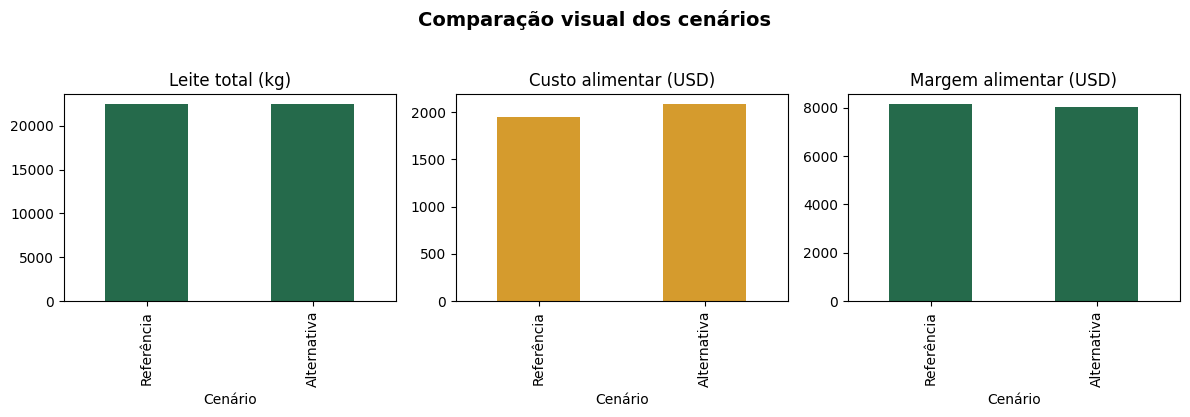

In [23]:
alternative = copy.deepcopy(reference)
alternative.name = 'dieta_alternativa'
ingredient_by_id = {item.feed_type: item for item in alternative.diet.ingredients}
ingredient_by_id[50].ration_percentage -= 2.0  # silagem de milho
ingredient_by_id[44].ration_percentage += 2.0  # milho moído
validate_simulation_config(alternative)
alternative_job = submit_simulation(alternative, SHARED_ROOT)
wait_for_simulation(alternative_job, SHARED_ROOT, timeout_seconds=1800)
alternative_result = load_result(alternative_job, SHARED_ROOT)
alternative_economics = calculate_economics(alternative_result, alternative)
comparison = compare_scenarios({
    'Referência': (reference_result, reference_economics),
    'Alternativa': (alternative_result, alternative_economics),
})
comparison_display = comparison.rename(columns={
    'milk_kg': 'Leite total (kg)',
    'average_daily_milk_kg': 'Média de leite (kg/dia)',
    'feed_cost': 'Custo alimentar (USD)',
    'milk_revenue': 'Receita do leite (USD)',
    'margin_over_feed_cost': 'Margem alimentar (USD)',
}).rename_axis('Cenário')
comparison_style = (
    comparison_display.style
    .set_caption('Comparação dos cenários simulados')
    .set_table_styles(TABLE_STYLES)
    .format('{:,.2f}')
)
display(comparison_style)
comparison_display[[
    'Leite total (kg)', 'Custo alimentar (USD)', 'Margem alimentar (USD)'
]].plot.bar(figsize=(12, 4), subplots=True, layout=(1, 3), legend=False, color=['#256a4b', '#d59b2d'])
plt.suptitle('Comparação visual dos cenários', y=1.03, fontsize=14, fontweight='bold')
plt.xlabel('Cenário')
plt.tight_layout()

## Próximos passos

A Etapa 2 está implementada em `02_otimizacao_dieta.ipynb`: nela, as quantidades dos ingredientes são variáveis de decisão e o RuFaS formula uma dieta de menor custo sob restrições NASEM. Na Etapa 3, esta mesma fila poderá executar variações sistemáticas para análise de sensibilidade.